# Time Series and Graphs as Structured Data
## Order, adjacency, and why “just a table” can be misleading

**Practical 7 — core approximately 65–70 minutes, optional extension up to 85 minutes**

This practical continues the representation theme from Practical 6 with two modalities whose
structure is easy to destroy:

- **time series** — order, time gaps, sampling interval, causality
- **graphs** — adjacency, paths, connectivity, edge meaning

> A time series is not merely a column of numbers, and a graph is not merely a matrix.

We will use one small synthetic system throughout: a network of environmental sensors.

### Learning outcomes

After this session you should be able to:

1. treat timestamps as part of the data model rather than decorative labels
2. sort, align and resample time-indexed data
3. create rolling and lagged features without using future information
4. explain why random shuffling can break temporal reasoning
5. represent a graph as an edge list and adjacency matrix
6. compute degree, connected components and shortest paths
7. distinguish fewest-edge paths from weighted shortest paths
8. explain what is preserved and lost when structured data become feature vectors

### Requirements

Core: `numpy`, `pandas`, `matplotlib`, `networkx`.

The notebook generates its own small dataset.

### Session plan

| Time | Part | Main idea |
|---|---|---|
| 0–10 min | 1. Structured observations | order and relations are part of the object |
| 10–35 min | 2. Time series | gaps, resampling, rolling, lags, temporal split |
| 35–60 min | 3. Graphs | edge list, adjacency, degree, components, shortest paths |
| 60–70 min | 4. Exit challenge | connect temporal and graph representations |
| 70–85 min | 5. Optional | graph Laplacian + multimodal feature table |

The **core is Parts 1–4**.

---
## 0. Environment

In [1]:
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import networkx as nx
except ImportError as exc:
    raise ImportError(
        "This practical requires networkx. Install it with: pip install networkx"
    ) from exc

print("Python:   ", sys.version.split()[0])
print("NumPy:    ", np.__version__)
print("pandas:   ", pd.__version__)
print("NetworkX: ", nx.__version__)
print("Platform: ", platform.platform())

Python:    3.13.5
NumPy:     2.3.5
pandas:    2.2.3
NetworkX:  3.6.1
Platform:  Linux-6.18.55-x86_64-with-glibc2.41


---
## 1. Structured observations

For many ordinary tables, row order is irrelevant.

That is not true for every modality.

### Time series

A sampled time series is a sequence

\[
(y_1,\ldots,y_T)
\]

indexed by time. Its structure includes order, sampling interval, gaps, and often causality.

### Graph

A graph

\[
G=(V,E)
\]

contains objects in \(V\) and relations in \(E\). Its structure includes adjacency, paths and
connectivity.

In both cases, important information lives **between observations**, not only inside each row.

In [2]:
rng = np.random.default_rng(2026)

timestamps = pd.date_range(
    "2026-10-01",
    periods=7 * 24 * 4,
    freq="15min",
)

hours = np.arange(len(timestamps)) / 4
daily_cycle = 4 * np.sin(2 * np.pi * hours / 24)

sensor_offsets = {
    "North": -1.0,
    "Central": 0.0,
    "East": 0.8,
    "West": 0.4,
}

rows = []

for sensor, offset in sensor_offsets.items():
    temperature = (
        18
        + offset
        + daily_cycle
        + rng.normal(0, 0.7, len(timestamps))
    )

    for timestamp, value in zip(timestamps, temperature):
        rows.append((timestamp, sensor, value))

sensor_raw = pd.DataFrame(
    rows,
    columns=["timestamp", "sensor", "temperature_c"],
)

missing_idx = rng.choice(sensor_raw.index, size=30, replace=False)

sensor_data = (
    sensor_raw
    .drop(index=missing_idx)
    .sample(frac=1.0, random_state=7)  # deliberately scramble row order
    .reset_index(drop=True)
)

sensor_data.head()

,timestamp,sensor,temperature_c
0,2026-10-02 05:15:00,West,22.425035
1,2026-10-07 20:45:00,West,16.018069
2,2026-10-04 02:45:00,North,19.824844
3,2026-10-03 14:15:00,West,15.762515
4,2026-10-06 14:15:00,Central,17.306465


The table contains timestamps, but the rows are intentionally scrambled.

A line plot in the current row order would connect observations in arbitrary order.

> If order matters, make the order explicit before temporal operations.

---
## 2. Time series — the index is part of the representation

In [3]:
central = (
    sensor_data
    .loc[sensor_data["sensor"] == "Central", ["timestamp", "temperature_c"]]
    .sort_values("timestamp")
    .set_index("timestamp")
)

central.head()

,temperature_c
timestamp,
2026-10-01 00:00:00,17.646771
2026-10-01 00:15:00,18.265008
2026-10-01 00:30:00,18.315221
2026-10-01 00:45:00,17.074764
2026-10-01 01:00:00,19.279811


### 2.1 Inspect the time grid

A series may look regular while still containing gaps.

The difference between consecutive timestamps is itself diagnostic.

In [4]:
time_steps = central.index.to_series().diff()
time_steps.value_counts().head()

timestamp
0 days 00:15:00    647
0 days 00:30:00     12
Name: count, dtype: int64

Most steps are 15 minutes. Larger gaps reveal missing observations.

`10 rows` does not necessarily mean `10 × 15 minutes` unless the grid is regular and complete.

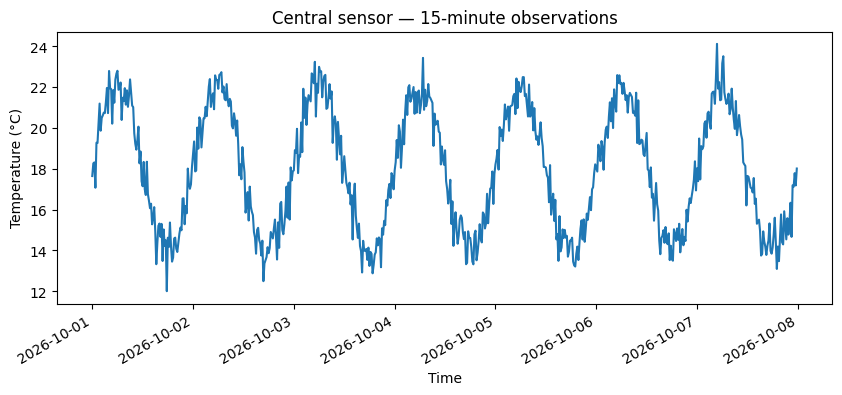

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))

central["temperature_c"].plot(ax=ax)

ax.set(
    title="Central sensor — 15-minute observations",
    xlabel="Time",
    ylabel="Temperature (°C)",
)

plt.show()

### 2.2 Resampling changes temporal resolution

We can represent the same process at an hourly scale:

\[
\text{15-minute observations}
\longrightarrow
\text{hourly summary}.
\]

This preserves some low-frequency structure and discards within-hour variation.

In [6]:
hourly = central.resample("1h").agg(
    temperature_mean=("temperature_c", "mean"),
    observations=("temperature_c", "count"),
)

hourly.head(10)

,temperature_mean,observations
timestamp,,
2026-10-01 00:00:00,17.825441,4
2026-10-01 01:00:00,19.994887,4
2026-10-01 02:00:00,20.432077,4
2026-10-01 03:00:00,21.176059,4
2026-10-01 04:00:00,21.714396,4
2026-10-01 05:00:00,22.031114,4
2026-10-01 06:00:00,22.205640,4
2026-10-01 07:00:00,21.286694,4
2026-10-01 08:00:00,21.408757,4


The observation count matters. An hourly mean based on four measurements and one based on a
single measurement are not equally supported.

In [7]:
hourly["observations"].value_counts().sort_index()

observations
3     12
4    156
Name: count, dtype: int64

### 2.3 Rolling windows summarize local history

A time-based rolling window uses recent observations according to timestamps.

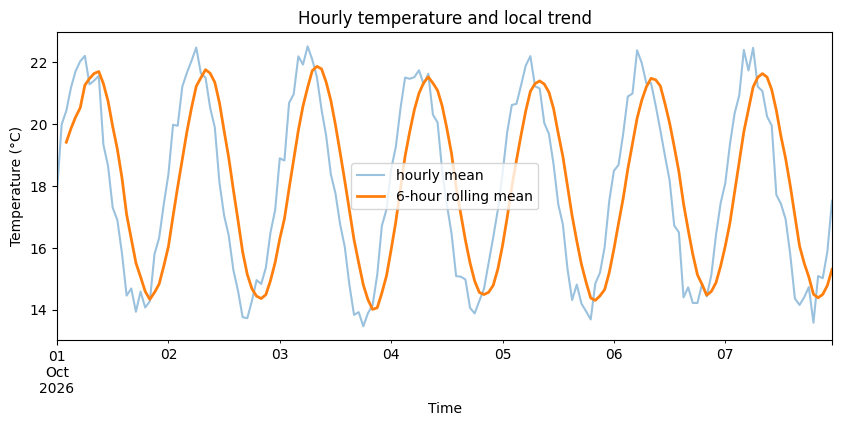

In [8]:
hourly["rolling_6h"] = (
    hourly["temperature_mean"]
    .rolling("6h", min_periods=3)
    .mean()
)

fig, ax = plt.subplots(figsize=(10, 4))

hourly["temperature_mean"].plot(
    ax=ax,
    alpha=0.45,
    label="hourly mean",
)

hourly["rolling_6h"].plot(
    ax=ax,
    linewidth=2,
    label="6-hour rolling mean",
)

ax.set(
    title="Hourly temperature and local trend",
    xlabel="Time",
    ylabel="Temperature (°C)",
)

ax.legend()
plt.show()

The rolling mean is smoother because it discards short-term variation.

A feature is therefore a **representation choice**, not a neutral copy of the source.

### 2.4 Lag features encode temporal relationships

A lagged value \(x_{t-1}\) means “the previous observed value”.

`shift(1)` keeps the time index fixed and moves values by one row.

In [9]:
hourly["previous_hour"] = hourly["temperature_mean"].shift(1)

hourly[["temperature_mean", "previous_hour"]].head()

,temperature_mean,previous_hour
timestamp,,
2026-10-01 00:00:00,17.825441,NaN
2026-10-01 01:00:00,19.994887,17.825441
2026-10-01 02:00:00,20.432077,19.994887
2026-10-01 03:00:00,21.176059,20.432077
2026-10-01 04:00:00,21.714396,21.176059


A causality rule:

> features for time \(t\) should not use information from \(t+1\) if the task is meant to operate
> in real time.

`shift(-1)` exposes a future value. That may be legitimate retrospectively, but it is future leakage
in a forecasting pipeline.

### Exercise A — temporal feature engineering

Create:

1. a `24h` rolling mean
2. a one-day lag on the hourly representation
3. a boolean feature telling whether the current temperature is above its 24-hour rolling mean

Then answer:

> Which of these features could be computed online at time \(t\) without future information?

In [10]:
# Your solution starts here.

### 2.5 Why random shuffling can be wrong

For independent survey respondents, shuffling rows may be harmless.

For time series, a random split can mix future observations into training data and earlier observations
into test data.

A chronological split preserves the direction of time.

In [11]:
split_time = hourly.index[int(len(hourly) * 0.8)]

train = hourly.loc[hourly.index < split_time]
test = hourly.loc[hourly.index >= split_time]

print("train:", train.index.min(), "→", train.index.max())
print("test: ", test.index.min(), "→", test.index.max())

train: 2026-10-01 00:00:00 → 2026-10-06 13:00:00
test:  2026-10-06 14:00:00 → 2026-10-07 23:00:00


---
## 3. Graphs — relations are part of the data

Now use the same sensors in another modality.

The sensors communicate through links. Each edge has:

- two endpoints
- a physical distance in kilometres

The graph represents the **network**, not the temperature history.

In [12]:
edges = pd.DataFrame(
    [
        ("North", "Central", 4.0),
        ("Central", "East", 3.0),
        ("Central", "West", 5.0),
        ("East", "West", 7.0),
    ],
    columns=["source", "target", "distance_km"],
)

edges

,source,target,distance_km
0,North,Central,4.0
1,Central,East,3.0
2,Central,West,5.0
3,East,West,7.0


### 3.1 Edge list → graph object

An edge list is convenient for storage and exchange.

NetworkX gives us a graph object for graph operations.

In [13]:
G = nx.from_pandas_edgelist(
    edges,
    source="source",
    target="target",
    edge_attr="distance_km",
    create_using=nx.Graph,
)

print("nodes:", list(G.nodes))
print("edges:", list(G.edges(data=True)))

nodes: ['North', 'Central', 'East', 'West']
edges: [('North', 'Central', {'distance_km': 4.0}), ('Central', 'East', {'distance_km': 3.0}), ('Central', 'West', {'distance_km': 5.0}), ('East', 'West', {'distance_km': 7.0})]


### 3.2 The same graph as an adjacency matrix

Fix an ordering of vertices:

```text
North, Central, East, West
```

Then an adjacency matrix records whether each pair is connected.

In [14]:
node_order = ["North", "Central", "East", "West"]

A = nx.to_numpy_array(
    G,
    nodelist=node_order,
    weight=None,
    dtype=int,
)

pd.DataFrame(
    A,
    index=node_order,
    columns=node_order,
)

,North,Central,East,West
North,0,1,0,0
Central,1,0,1,1
East,0,1,0,1
West,0,1,1,0


For this simple undirected graph:

- the matrix is symmetric
- the diagonal is zero
- `1` means an edge exists

The edge list and adjacency matrix encode the same finite graph once node ordering is fixed, but they
support different operations efficiently.

### 3.3 Degree is a local graph feature

In [15]:
degree_table = (
    pd.Series(dict(G.degree), name="degree")
    .rename_axis("sensor")
    .sort_values(ascending=False)
    .to_frame()
)

degree_table

,degree
sensor,
Central,3
East,2
West,2
North,1


Degree counts incident edges.

It is a useful local descriptor, but it does **not** automatically mean “importance”.
That interpretation depends on the task.

### 3.4 Connectivity is a global property

In [16]:
components = list(nx.connected_components(G))

print("number of connected components:", len(components))
print("components:", components)

number of connected components: 1
components: [{'Central', 'East', 'North', 'West'}]


Now remove one communication link.

In [17]:
G_failure = G.copy()
G_failure.remove_edge("North", "Central")

failure_components = list(nx.connected_components(G_failure))

print("after failure:", failure_components)

after failure: [{'North'}, {'East', 'Central', 'West'}]


The sensor values and node names did not change.

Only one relation changed, yet the graph became disconnected.

Relational structure cannot be treated as independent rows without consequence.

### 3.5 Shortest path depends on what “shortest” means

In an unweighted graph, shortest usually means:

> fewest edges.

With weights, shortest can mean:

> minimum total distance.

These are different geometries.

In [18]:
unweighted_path = nx.shortest_path(
    G,
    source="North",
    target="West",
)

weighted_path = nx.shortest_path(
    G,
    source="North",
    target="West",
    weight="distance_km",
)

weighted_distance = nx.shortest_path_length(
    G,
    source="North",
    target="West",
    weight="distance_km",
)

print("fewest edges:", unweighted_path)
print("minimum distance:", weighted_path)
print("weighted distance:", weighted_distance, "km")

fewest edges: ['North', 'Central', 'West']
minimum distance: ['North', 'Central', 'West']
weighted distance: 9.0 km


The algorithm is not enough by itself.

The edge meaning matters:

```text
1 edge
```

and

```text
1 kilometre
```

are different notions of closeness.

### Exercise B — network failure

Remove the edge:

```text
Central — West
```

Then answer:

1. Does the graph remain connected?
2. What is the new unweighted shortest path from `North` to `West`?
3. What is the new weighted distance?
4. Why is a 0/1 adjacency matrix insufficient to recover kilometre-based shortest paths?

In [19]:
# Your solution starts here.

---
## 4. One system, two modalities

We now have two different objects describing the same physical system.

### Time-series view

```text
sensor
→ values over time
```

This exposes trends, lags, temporal variability and missing intervals.

### Graph view

```text
sensor
→ relations to other sensors
```

This exposes degree, connectivity, paths and network failures.

Neither is “the complete data”.

### Bridge: structured objects → feature vectors

Later methods such as PCA or clustering usually expect

\[
X \in \mathbb{R}^{n\times d}.
\]

We can summarize each sensor with features such as:

```text
mean temperature
temperature standard deviation
missingness rate
degree
mean neighbour distance
```

This makes ordinary numerical algorithms possible, but it is lossy:

- summaries discard most temporal order
- degree discards the exact graph neighbourhood

Feature engineering is another representation map.

### Exit challenge — structure audit

Complete this table in Markdown:

| Question | Time series | Graph |
|---|---|---|
| Original structure |  |  |
| Natural storage form |  |  |
| What would arbitrary row/node reordering change? |  |  |
| One useful derived feature |  |  |
| What does that feature discard? |  |  |
| One meaningful distance / comparison |  |  |
| One failure mode caused by ignoring structure |  |  |

Then write three short conclusions:

1. why a shuffled time series is not generally equivalent to the original
2. why an adjacency matrix needs a node ordering
3. why reducing a structured modality to a feature vector can be useful but lossy

In [20]:
# Optional: use this cell for calculations supporting the exit challenge.

---
## 5. Optional extension — graph algebra and multimodal features

Skip this section if the core practical has already used the available class time.

### 5.1 Graph Laplacian

For an undirected graph,

\[
L=D-A,
\]

where \(A\) is the adjacency matrix and \(D\) is the degree matrix.

A useful theorem from the graph lecture is:

> the multiplicity of eigenvalue 0 equals the number of connected components.

In [21]:
A = nx.to_numpy_array(
    G,
    nodelist=node_order,
    weight=None,
)

D = np.diag(A.sum(axis=1))
L = D - A

eigenvalues = np.linalg.eigvalsh(L)

print("Laplacian:")
display(pd.DataFrame(L, index=node_order, columns=node_order))
print("eigenvalues:", np.round(eigenvalues, 6))
print("near-zero eigenvalues:", np.isclose(eigenvalues, 0).sum())

Laplacian:


,North,Central,East,West
North,1.0,-1.0,0.0,0.0
Central,-1.0,3.0,-1.0,-1.0
East,0.0,-1.0,2.0,-1.0
West,0.0,-1.0,-1.0,2.0


eigenvalues: [-0.  1.  3.  4.]
near-zero eigenvalues: 1


In [22]:
A_failure = nx.to_numpy_array(
    G_failure,
    nodelist=node_order,
    weight=None,
)

L_failure = np.diag(A_failure.sum(axis=1)) - A_failure
failure_eigenvalues = np.linalg.eigvalsh(L_failure)

print("failure eigenvalues:", np.round(failure_eigenvalues, 6))
print("near-zero eigenvalues:", np.isclose(failure_eigenvalues, 0).sum())

failure eigenvalues: [-0.  0.  3.  3.]
near-zero eigenvalues: 2


The connected graph has one near-zero eigenvalue. After isolating `North`, there are two connected
components and two near-zero eigenvalues.

This is a bridge from graph structure back to linear algebra.

### 5.2 One feature row per sensor

Now compress the temporal and relational views into a single ordinary table.

In [23]:
temporal_features = (
    sensor_data
    .groupby("sensor")
    .agg(
        mean_temperature=("temperature_c", "mean"),
        std_temperature=("temperature_c", "std"),
        n_observations=("temperature_c", "size"),
    )
)

graph_features = pd.DataFrame(
    {
        "degree": pd.Series(dict(G.degree)),
        "mean_neighbor_distance": pd.Series(
            {
                node: np.mean(
                    [
                        attrs["distance_km"]
                        for _, _, attrs in G.edges(node, data=True)
                    ]
                )
                for node in G.nodes
            }
        ),
    }
)

sensor_features = temporal_features.join(graph_features)

sensor_features

,mean_temperature,std_temperature,n_observations,degree,mean_neighbor_distance
sensor,,,,,
Central,17.993190,2.930961,660,3,4.0
East,18.731466,2.930468,668,2,5.0
North,17.009403,2.946725,664,1,4.0
West,18.379735,2.876221,666,2,6.0


This feature table is convenient, but it no longer contains:

- the full temperature trajectory
- exact timestamps
- the exact graph neighbourhood of each node

Convenience and information preservation are different objectives.

---
## Summary

### 1. Time is structure

A time series includes order, spacing and often a causal direction.

`resample`, `rolling` and `shift` create new temporal representations.

### 2. Relations are structure

A graph includes adjacency, connectivity and paths.

Edge lists and adjacency matrices can encode the same graph, but support different computations.

### 3. Distance depends on representation

- one hour versus one row
- one edge versus one kilometre

are different notions of closeness.

### 4. Feature vectors are useful but lossy

Structured objects can be summarized into ordinary numerical features, but the discarded structure
must be understood.

The next step is **Lab 2 — Processing Data of Different Modalities**, where the same representation
audit will be applied more independently.

### Further reading

- [pandas: Time series / date functionality](https://pandas.pydata.org/docs/user_guide/timeseries.html)
- [pandas: Windowing operations](https://pandas.pydata.org/docs/user_guide/window.html)
- [NetworkX documentation](https://networkx.org/documentation/stable/)
- [NetworkX shortest paths](https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html)
- [NetworkX linear algebra / graph matrices](https://networkx.org/documentation/stable/reference/linalg.html)